<a href="https://colab.research.google.com/github/Kirthiga19/RNN-/blob/main/IMDB_LSTM_Sentiment_Analysis.ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import re
import json
import html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score
)

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))


TensorFlow version: 2.21.0
GPU available: False


In [ ]:

from google.colab import files

uploaded = files.upload()

csv_filename = next(
    (f for f in uploaded.keys() if f.lower().endswith(".csv")),
    None
)

if csv_filename is None:
    raise ValueError("Upload your IMDB CSV file.")

print("Dataset uploaded:", csv_filename)


Saving IMDB Dataset.csv to IMDB Dataset.csv
Dataset uploaded: IMDB Dataset.csv


In [ ]:

df = pd.read_csv(csv_filename)

df.columns = df.columns.str.strip().str.lower()

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())
print("\nMissing values:\n", df.isnull().sum())


Dataset shape: (50000, 2)
Columns: ['review', 'sentiment']


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive



Missing values:
 review       0
sentiment    0
dtype: int64


In [ ]:

review_candidates = ["review", "reviews", "text", "content"]
label_candidates = ["sentiment", "label", "polarity", "target"]

review_col = next(
    (c for c in review_candidates if c in df.columns), None
)
label_col = next(
    (c for c in label_candidates if c in df.columns), None
)

if review_col is None or label_col is None:
    raise ValueError(
        "Could not find review and sentiment columns. "
        f"Found columns: {df.columns.tolist()}"
    )

df = df[[review_col, label_col]].copy()
df.columns = ["review", "sentiment"]

df = df.dropna(subset=["review", "sentiment"])
df["review"] = df["review"].astype(str)
df["sentiment"] = df["sentiment"].astype(str).str.strip().str.lower()

label_map = {
    "negative": 0,
    "positive": 1,
    "neg": 0,
    "pos": 1,
    "0": 0,
    "1": 1
}

df["sentiment"] = df["sentiment"].map(label_map)
df = df.dropna(subset=["sentiment"])
df["sentiment"] = df["sentiment"].astype("int32")

def clean_text(text):
    text = html.unescape(text)
    text = re.sub(r"<br\s*/?>", " ", text, flags=re.I)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["review"] = df["review"].apply(clean_text)
df = df[df["review"].str.len() > 0]
df = df.drop_duplicates(subset=["review"]).reset_index(drop=True)

if set(df["sentiment"].unique()) != {0, 1}:
    raise ValueError(
        "Both positive and negative labels must be present. "
        "Check your original label values."
    )

print("Clean dataset:", df.shape)
print("\nSentiment distribution:")
print(df["sentiment"].value_counts().rename(index={0: "Negative", 1: "Positive"}))
display(df.head())


Clean dataset: (49578, 2)

Sentiment distribution:
sentiment
Positive    24882
Negative    24696
Name: count, dtype: int64


,review,sentiment
0,One of the other reviewers has mentioned that ...,1
1,A wonderful little production. The filming tec...,1
2,I thought this was a wonderful way to spend ti...,1
3,Basically there's a family where a little boy ...,0
4,"Petter Mattei's ""Love in the Time of Money"" is...",1


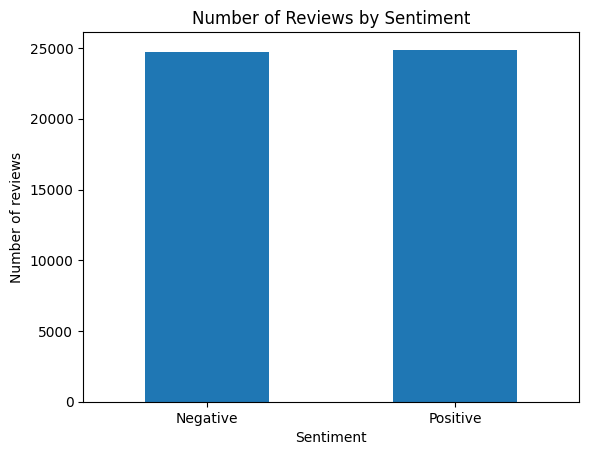

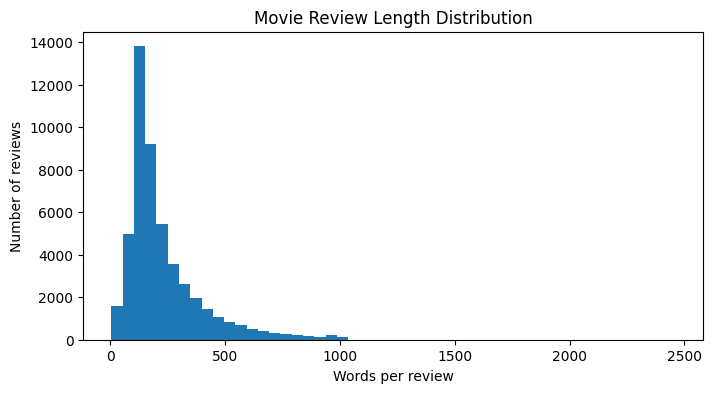

                                              review  sentiment  review_length
0  One of the other reviewers has mentioned that ...          1            304
1  A wonderful little production. The filming tec...          1            156
2  I thought this was a wonderful way to spend ti...          1            164
3  Basically there's a family where a little boy ...          0            135
4  Petter Mattei's "Love in the Time of Money" is...          1            225


In [ ]:

df["review_length"] = df["review"].apply(lambda text: len(text.split()))

df["sentiment"].value_counts().sort_index().rename(
    index={0: "Negative", 1: "Positive"}
).plot(kind="bar")

plt.title("Number of Reviews by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of reviews")
plt.xticks(rotation=0)
plt.show()

plt.figure(figsize=(8, 4))
plt.hist(df["review_length"], bins=50)
plt.title("Movie Review Length Distribution")
plt.xlabel("Words per review")
plt.ylabel("Number of reviews")
plt.show()

print(df[["review", "sentiment", "review_length"]].head())


In [ ]:

X = df["review"].values
y = df["sentiment"].values

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))


Training samples: 34704
Validation samples: 7437
Testing samples: 7437


In [ ]:

VOCAB_SIZE = 20000
MAX_LENGTH = 250
EMBEDDING_DIM = 64

tokenizer = Tokenizer(
    num_words=VOCAB_SIZE,
    oov_token="<OOV>"
)

# Learn vocabulary only from training reviews
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(
    X_train_seq, maxlen=MAX_LENGTH,
    padding="post", truncating="post"
)
X_val_pad = pad_sequences(
    X_val_seq, maxlen=MAX_LENGTH,
    padding="post", truncating="post"
)
X_test_pad = pad_sequences(
    X_test_seq, maxlen=MAX_LENGTH,
    padding="post", truncating="post"
)

print("Training input:", X_train_pad.shape)
print("Validation input:", X_val_pad.shape)
print("Testing input:", X_test_pad.shape)


Training input: (34704, 250)
Validation input: (7437, 250)
Testing input: (7437, 250)


In [ ]:

model = Sequential([
    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM,
        mask_zero=True
    ),
    LSTM(64),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.build(input_shape=(None, MAX_LENGTH))
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 250, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,315,137 (5.02 MB)

 Trainable params: 1,315,137 (5.02 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
    verbose=1
)

checkpoint = ModelCheckpoint(
    "best_imdb_lstm.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

history = model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=8,
    batch_size=64,
    callbacks=[early_stopping, checkpoint],
    verbose=1
)


Epoch 1/8
543/543 ━━━━━━━━━━━━━━━━━━━━ 0s 249ms/step - accuracy: 0.7401 - loss: 0.4939
Epoch 1: val_loss improved from None to 0.32811, saving model to best_imdb_lstm.keras

Epoch 1: finished saving model to best_imdb_lstm.keras
543/543 ━━━━━━━━━━━━━━━━━━━━ 150s 269ms/step - accuracy: 0.8228 - loss: 0.3925 - val_accuracy: 0.8594 - val_loss: 0.3281
Epoch 2/8
543/543 ━━━━━━━━━━━━━━━━━━━━ 0s 247ms/step - accuracy: 0.9008 - loss: 0.2662
Epoch 2: val_loss improved from 0.32811 to 0.31399, saving model to best_imdb_lstm.keras

Epoch 2: finished saving model to best_imdb_lstm.keras
543/543 ━━━━━━━━━━━━━━━━━━━━ 196s 259ms/step - accuracy: 0.9062 - loss: 0.2538 - val_accuracy: 0.8681 - val_loss: 0.3140
Epoch 3/8
543/543 ━━━━━━━━━━━━━━━━━━━━ 0s 246ms/step - accuracy: 0.9260 - loss: 0.2001
Epoch 3: val_loss did not improve from 0.31399
543/543 ━━━━━━━━━━━━━━━━━━━━ 141s 261ms/step - accuracy: 0.9260 - loss: 0.2003 - val_accuracy: 0.8412 - val_loss: 0.4586
Epoch 4/8
543/543 ━━━━━━━━━━━━━━━━━━━━ 0s 

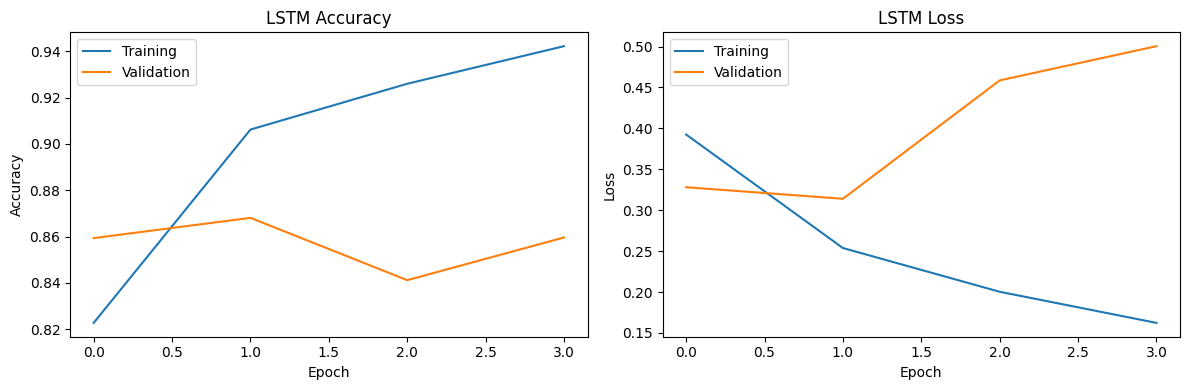

In [10]:

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("LSTM Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("LSTM Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


233/233 ━━━━━━━━━━━━━━━━━━━━ 15s 60ms/step - accuracy: 0.8706 - loss: 0.3059
233/233 ━━━━━━━━━━━━━━━━━━━━ 10s 43ms/step

Test loss: 0.3059
Test accuracy: 87.06%
Precision: 0.8786
Recall: 0.8612
F1-score: 0.8698

Classification Report:
              precision    recall  f1-score   support

    Negative       0.86      0.88      0.87      3705
    Positive       0.88      0.86      0.87      3732

    accuracy                           0.87      7437
   macro avg       0.87      0.87      0.87      7437
weighted avg       0.87      0.87      0.87      7437



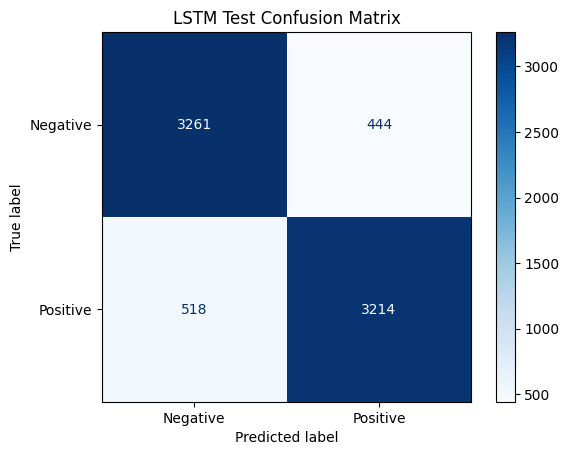

In [11]:

model = load_model("best_imdb_lstm.keras")

test_loss, test_accuracy = model.evaluate(
    X_test_pad, y_test, verbose=1
)

y_prob = model.predict(X_test_pad, verbose=1).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print(f"\nTest loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall: {recall_score(y_test, y_pred):.4f}")
print(f"F1-score: {f1_score(y_test, y_pred):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Negative", "Positive"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
).plot(cmap="Blues")

plt.title("LSTM Test Confusion Matrix")
plt.show()


In [12]:

def predict_sentiment(review):
    sequence = tokenizer.texts_to_sequences([review])

    padded = pad_sequences(
        sequence,
        maxlen=MAX_LENGTH,
        padding="post",
        truncating="post"
    )

    probability = float(model.predict(padded, verbose=0)[0][0])
    sentiment = "Positive" if probability >= 0.5 else "Negative"

    print("\nReview:", review)
    print("Predicted sentiment:", sentiment)
    print(f"Positive score: {probability:.2%}")

    return sentiment, probability


predict_sentiment(
    "The movie was amazing and the acting was excellent."
)

predict_sentiment(
    "The film was boring, disappointing, and badly directed."
)

predict_sentiment(
    "The story was good but the ending was terrible."
)



Review: The movie was amazing and the acting was excellent.
Predicted sentiment: Positive
Positive score: 95.31%

Review: The film was boring, disappointing, and badly directed.
Predicted sentiment: Negative
Positive score: 0.29%

Review: The story was good but the ending was terrible.
Predicted sentiment: Negative
Positive score: 7.87%


('Negative', 0.07868340611457825)

In [13]:

model.save("imdb_lstm_final.keras")

with open("imdb_tokenizer.json", "w", encoding="utf-8") as f:
    f.write(tokenizer.to_json())

print("Saved model: imdb_lstm_final.keras")
print("Saved tokenizer: imdb_tokenizer.json")


Saved model: imdb_lstm_final.keras
Saved tokenizer: imdb_tokenizer.json


In [14]:

from google.colab import files

files.download("imdb_lstm_final.keras")
files.download("imdb_tokenizer.json")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:

model = tf.keras.models.load_model("best_imdb_lstm.keras")

test_loss, test_accuracy = model.evaluate(
    X_test_pad,
    y_test,
    verbose=1
)

print("=" * 40)
print(f"FINAL TEST ACCURACY: {test_accuracy * 100:.2f}%")
print(f"TEST LOSS: {test_loss:.4f}")
print("=" * 40)


233/233 ━━━━━━━━━━━━━━━━━━━━ 13s 53ms/step - accuracy: 0.8706 - loss: 0.3059
FINAL TEST ACCURACY: 87.06%
TEST LOSS: 0.3059
